# NB03 — Full-mosaic M2 Musanga probability inference

Frozen final all-30 M2 by default, optional 3-fold CV ensemble, native RGB only. 256×256 input patches as trained, stride 128, globally anchored cosine feather blending, independent seam preflight, all audited mosaics including MOS3–4. Restartable stripes and protected existing products. No training. Ensemble is not itself cross-validated; do not attribute NB02B fold CV metrics to this ensemble.


## 01 — Input audit and frozen-checkpoint verification


In [2]:
%pip -q install rasterio segmentation-models-pytorch pandas matplotlib
import json,hashlib,os,shutil,time,math,warnings,gc
from pathlib import Path
import numpy as np,pandas as pd,rasterio,torch
from rasterio.windows import Window
from rasterio.errors import NodataShadowWarning
from tqdm.auto import tqdm
from IPython.display import display
from google.colab import drive
warnings.filterwarnings("once",category=NodataShadowWarning)
if not Path("/content/drive/MyDrive").exists(): drive.mount("/content/drive")
ROOT=next((p for p in (Path("/content/drive/MyDrive/Colab Notebooks/Musanga/Final"),Path("/content/drive/MyDrive/Musanga/Final")) if p.is_dir()),None)
assert ROOT is not None,"Missing Musanga/Final on Drive"
AUDIT=ROOT/"Outputs/V3/00_input_audit/00_input_manifest.json"
BASE=ROOT/"Outputs/V3/02B_spatial3fold_no_MOS34"
assert AUDIT.exists() and BASE.exists()
A=json.loads(AUDIT.read_text())
assert A.get("schema_version")=="v3_input_audit_5_nadine_circles"
assert torch.cuda.is_available(),"Choose a Colab GPU runtime"
import segmentation_models_pytorch as smp

class ResNet18UNet(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.net=smp.Unet(encoder_name="resnet18",encoder_weights=None,in_channels=3,classes=1)
    def forward(self,x): return self.net(x)[:,0]

MOSAICS={m["file"]:Path(m["path"]) for m in A["mosaics"]}
assert len(MOSAICS)>=6,("Expected all audited mosaics, including MOS3–4",list(MOSAICS))
assert all(p.exists() for p in MOSAICS.values())
INCLUDE_LUKI=False  # external to NB00; may enable explicitly
if INCLUDE_LUKI:
    source=ROOT.parent/"data/Geo_Ref/Luki.tif"
    assert source.exists(),source
    MOSAICS["Luki.tif"]=source
RUN_MOSAICS=list(MOSAICS)  # choose a subset to test before full production
assert set(RUN_MOSAICS).issubset(MOSAICS)

ref_file=BASE/"02B_latest_reference_version.json"
assert ref_file.exists()
ref=json.loads(ref_file.read_text())
assert ref["circles"]==30 and ref["sha256"]
scored=pd.read_csv(BASE/"02B_spatialCV_all30_paired.csv")
scored=scored[scored.model=="M2"]
assert len(scored)==30 and scored.circle_id.is_unique
def sha_file(p):
    h=hashlib.sha256()
    with open(p,"rb") as f:
        for piece in iter(lambda:f.read(8*1024*1024),b""): h.update(piece)
    return h.hexdigest()
# Explicit production choice. FINAL requires running NB02B Section 08 first.
MODEL_MODE='final_all30'  # alternatives: 'cv_ensemble'
assert MODEL_MODE in ('final_all30','cv_ensemble')
CHECKPOINTS=[]
if MODEL_MODE=='final_all30':
    final_dir=BASE/'final_all30_M2'
    manifest=final_dir/'02B_final_all30_manifest.json'
    assert manifest.exists(),('Run NB02B Section 08 to train final M2',manifest)
    config=json.loads(manifest.read_text())
    assert config['exhaustive_annotations_sha256']==ref['sha256'],('Reference version mismatch',manifest)
    assert len(config['circle_ids'])==30
    cp=Path(config['checkpoint'])
    assert cp.exists(),('Final all-30 M2 checkpoint missing',cp)
    CHECKPOINTS.append(dict(fold='FINAL_ALL30',path=str(cp),sha256=sha_file(cp)))
else:
    for fold in (0,1,2):
        matches=sorted((BASE/f'fold_{fold}').glob('M2_resnet18_spatialCV_*.pt'))
        assert len(matches)==1,('Resolve ambiguous/missing CV checkpoint',fold,matches)
        cp=matches[0]
        CHECKPOINTS.append(dict(fold=fold,path=str(cp),sha256=sha_file(cp)))
display(pd.DataFrame(CHECKPOINTS))
print("Audited input mosaics:",list(MOSAICS))
print('MODEL_MODE:',MODEL_MODE,'| frozen M2 native RGB | no illumination changes')
# NB02B consumes 0–1 RGB without additional ImageNet mean/std normalization.
TILE=256;STEP=128;CORE=512;STRIPE=1024;BATCH=12
SCALE=10000;NODATA=65535;EDGE_FLOOR=0.02
PIPELINE="NB03_M2_"+MODEL_MODE+"_native256_stride128_cosine_v2"
assert STEP==TILE//2 and CORE%STEP==0 and STRIPE%CORE==0
OUT=ROOT/("Outputs/V3/03_M2_full_mosaic_"+MODEL_MODE)
MAPS=OUT/"probability_maps";PARTS=OUT/"stripes"
MAPS.mkdir(parents=True,exist_ok=True);PARTS.mkdir(parents=True,exist_ok=True)
SCRATCH=Path("/content/nb03_scratch");SCRATCH.mkdir(exist_ok=True)
ENSEMBLE_SHA=hashlib.sha256("".join(z["sha256"] for z in CHECKPOINTS).encode()).hexdigest()


Mounted at /content/drive


,fold,path,sha256
0,FINAL_ALL30,/content/drive/MyDrive/Colab Notebooks/Musanga...,a5c9be9ef5a0c499828507fb58f69141fc27b27ec7a4d2...


Audited input mosaics: ['Baego.tif', 'Mos_1_2_transparent_mosaic_group1_georef.tif', 'Mos_3_4_transparent_mosaic_group1_georef.tif', 'Mos_5_6_transparent_mosaic_group1_georef.tif', 'Yangambi_georef.tif', 'Yoko_kvo_georef.tif']
MODEL_MODE: final_all30 | frozen M2 native RGB | no illumination changes


## 02 — Native-resolution 256-pixel inference with globally aligned cosine blending
Every mosaic pixel receives contributions from the same global tile lattice regardless of output block or stripe position. Checkpoint probabilities are averaged when multiple checkpoints are selected, never their logits. This is computationally expensive but avoids spatial-window mismatch from V2.


In [3]:
MODELS=[]
for x in CHECKPOINTS:
    model=ResNet18UNet().cuda()
    model.load_state_dict(torch.load(x["path"],map_location="cpu",weights_only=True),strict=True)
    model.eval()
    MODELS.append(model)
assert len(MODELS)==len(CHECKPOINTS) and len(MODELS) in (1,3)
u=np.arange(TILE,dtype="float32")+.5
u=EDGE_FLOOR+(1-EDGE_FLOOR)*np.sin(np.pi*u/TILE)**2
WEIGHT=(u[:,None]*u[None,:]).astype("float32")
assert WEIGHT.min()>0
def valid_rgb(raw):
    # MATCH NB02B: masked RGB bands, excluding exact all-black, all-white, blue.
    a=raw.filled(0).astype("float32")
    v=~np.any(np.ma.getmaskarray(raw),axis=0)
    v &= np.any(a!=0,axis=0)&np.any(a!=255,axis=0)
    v &= ~((a[0]==0)&(a[1]==0)&(a[2]==255))
    return v

def starts(lo,hi):
    return list(range((lo-TILE+1)//STEP*STEP,(hi-1)//STEP*STEP+1,STEP))

def infer_rect(src,r0,c0,h,w):
    """Globally anchored overlapping 256-pixel windows; no core-dependent seams."""
    assert 0<=r0<src.height and 0<=c0<src.width
    assert 0<h<=src.height-r0 and 0<w<=src.width-c0
    center=src.read([1,2,3],window=Window(c0,r0,w,h),masked=True)
    valid=valid_rgb(center)
    if not valid.any():
        return np.full((h,w),np.nan,"float32"),valid
    rs=starts(r0,r0+h);cs=starts(c0,c0+w)
    top=min(rs);left=min(cs);bottom=max(rs)+TILE;right=max(cs)+TILE
    ext=np.zeros((3,bottom-top,right-left),dtype="uint8")
    rr0=max(0,top);cc0=max(0,left)
    rr1=min(bottom,src.height);cc1=min(right,src.width)
    if rr1>rr0 and cc1>cc0:
        src_data=src.read([1,2,3],window=Window(cc0,rr0,cc1-cc0,rr1-rr0),masked=True)
        ext[:,rr0-top:rr1-top,cc0-left:cc1-left]=src_data.filled(0)
    total=np.zeros((h,w),dtype="float64")
    weights_total=np.zeros((h,w),dtype="float64")
    patches=[];tasks=[]
    def flush():
        if not patches:return
        batch=torch.from_numpy(np.stack(patches).astype("float32")/255.).cuda()
        ensemble=None
        with torch.inference_mode():
            for model in MODELS:
                with torch.autocast("cuda",dtype=torch.float16):
                    prediction=torch.sigmoid(model(batch)).float()
                ensemble=prediction if ensemble is None else ensemble+prediction
            predictions=(ensemble/len(MODELS)).cpu().numpy()
        for (tr,tc,cr0,cr1,ccr0,ccr1),prob in zip(tasks,predictions):
            pr0=cr0-(tr-r0);pc0=ccr0-(tc-c0)
            hh=cr1-cr0;ww=ccr1-ccr0
            wwgt=WEIGHT[pr0:pr0+hh,pc0:pc0+ww]
            pp=prob[pr0:pr0+hh,pc0:pc0+ww]
            total[cr0:cr1,ccr0:ccr1]+=wwgt*pp
            weights_total[cr0:cr1,ccr0:ccr1]+=wwgt
        patches.clear();tasks.clear()
    for tr in rs:
        for tc in cs:
            cr0=max(0,tr-r0);cr1=min(h,tr+TILE-r0)
            ccr0=max(0,tc-c0);ccr1=min(w,tc+TILE-c0)
            if cr0>=cr1 or ccr0>=ccr1:continue
            if not valid[cr0:cr1,ccr0:ccr1].any():continue
            patch=ext[:,tr-top:tr-top+TILE,tc-left:tc-left+TILE]
            assert patch.shape==(3,TILE,TILE)
            patches.append(patch);tasks.append((tr,tc,cr0,cr1,ccr0,ccr1))
            if len(patches)>=BATCH:flush()
    flush()
    assert np.all(weights_total[valid]>0),("Missing tile weight",r0,c0)
    p=np.full((h,w),np.nan,"float32")
    p[valid]=(total[valid]/weights_total[valid]).astype("float32")
    assert np.all(np.isfinite(p[valid])) and np.all((p[valid]>=0)&(p[valid]<=1))
    return p,valid

def to_u16(prob,valid):
    arr=np.full(prob.shape,NODATA,dtype="uint16")
    arr[valid]=np.rint(prob[valid]*SCALE).astype("uint16")
    assert np.array_equal(arr!=NODATA,valid)
    return arr


## 03 — Mandatory preflight against tiling seams
For each source mosaic, compute the same pixels in two **different, overlapping 512×512 output blocks**. The predicted values must match to 1e−4 despite shifted chunk boundaries. This catches incorrect tile-grid resets before any full-mosaic computation.


In [4]:
# Required seam preflight. Find representative VALID areas by scanning the
# mosaic on a coarse grid, not by guessing four diagonal locations.
# Check comparison geometry on real valid pixels; never silently skip a site.
PREFLIGHT_OK=False
PREFLIGHT=[]
for name in RUN_MOSAICS:
    with rasterio.open(MOSAICS[name]) as ds:
        assert ds.count>=3 and all(x=="uint8" for x in ds.dtypes[:3]),(name,ds.dtypes)
        assert ds.crs is not None
        if ds.height<512 or ds.width<768:
            raise RuntimeError(("Source too small for this 512px/768px seam diagnostic",name,ds.shape))

        # Survey 9x9 candidate origins across the true source extent.
        # Each probe reads only 256x256 pixels in the actual overlap, making
        # it much cheaper than running the neural network for all 81 locations.
        candidates=[]
        rows=np.unique(np.linspace(0,ds.height-512,9).astype(int))
        cols=np.unique(np.linspace(0,ds.width-768,9).astype(int))
        for row in rows:
            for col in cols:
                center=ds.read([1,2,3],window=Window(int(col)+256,int(row),256,256),masked=True)
                count=int(valid_rgb(center).sum())
                if count:
                    candidates.append((count,int(row),int(col)))
        candidates.sort(reverse=True)
        if not candidates:
            # No arbitrary lowering of the threshold: inspect the actual RGB
            # mask and source metadata if this case ever occurs.
            raise RuntimeError((
                "No valid RGB pixels in any of 81 spread-out overlap probes",
                name,ds.width,ds.height,ds.nodata,ds.mask_flag_enums))
        best_count,row,col=candidates[0]
        print(f"PREFLIGHT {name}: best 256x256 overlap probe = "
              f"{best_count:,}/65,536 valid pixels; row={row}, col={col}",flush=True)

        # Different output-core origins, identical global input tile lattice.
        # Pixels in the shared 512x256 area MUST have identical probabilities.
        p0,v0=infer_rect(ds,row,col,512,512)
        p1,v1=infer_rect(ds,row,col+256,512,512)
        both=v0[:,256:]&v1[:,:256]
        n=int(both.sum())
        assert n>=best_count,(name,"unexpected mask difference",n,best_count)
        difference=np.abs(p0[:,256:][both]-p1[:,:256][both])
        maxdiff=float(difference.max())
        meandiff=float(difference.mean())
        assert np.isfinite(maxdiff) and maxdiff<1e-4,(
            "SEAM FAILURE: identical geographic pixels differ across output-block origins",
            name,maxdiff,meandiff,n)
        PREFLIGHT.append(dict(mosaic=name,crs=str(ds.crs),valid_probe_pixels=best_count,
               common_valid_pixels=n,max_abs_probability_diff=maxdiff,
               mean_abs_probability_diff=meandiff,row=row,col=col,status="PASS"))
        print(f"PASS {name}: {n:,} common valid pixels; "
              f"max difference {maxdiff:.8f}",flush=True)

assert len(PREFLIGHT)==len(RUN_MOSAICS)
display(pd.DataFrame(PREFLIGHT))
(OUT/"03_seam_preflight.json").write_text(json.dumps(PREFLIGHT,indent=2))
PREFLIGHT_OK=True
print("All mosaic seam tests PASS; production is now enabled.")


PREFLIGHT Baego.tif: best 256x256 overlap probe = 65,536/65,536 valid pixels; row=7597, col=78049
PASS Baego.tif: 131,072 common valid pixels; max difference 0.00000000
PREFLIGHT Mos_1_2_transparent_mosaic_group1_georef.tif: best 256x256 overlap probe = 65,536/65,536 valid pixels; row=21625, col=55261
PASS Mos_1_2_transparent_mosaic_group1_georef.tif: 117,380 common valid pixels; max difference 0.00000000
PREFLIGHT Mos_3_4_transparent_mosaic_group1_georef.tif: best 256x256 overlap probe = 65,536/65,536 valid pixels; row=23926, col=45806
PASS Mos_3_4_transparent_mosaic_group1_georef.tif: 112,864 common valid pixels; max difference 0.00000000
PREFLIGHT Mos_5_6_transparent_mosaic_group1_georef.tif: best 256x256 overlap probe = 65,536/65,536 valid pixels; row=39243, col=23153
PASS Mos_5_6_transparent_mosaic_group1_georef.tif: 89,275 common valid pixels; max difference 0.00000000
PREFLIGHT Yangambi_georef.tif: best 256x256 overlap probe = 65,536/65,536 valid pixels; row=32305, col=88417
PAS

,mosaic,crs,valid_probe_pixels,common_valid_pixels,max_abs_probability_diff,mean_abs_probability_diff,row,col,status
0,Baego.tif,EPSG:32635,65536,131072,0.0,0.0,7597,78049,PASS
1,Mos_1_2_transparent_mosaic_group1_georef.tif,EPSG:32635,65536,117380,0.0,0.0,21625,55261,PASS
2,Mos_3_4_transparent_mosaic_group1_georef.tif,EPSG:32635,65536,112864,0.0,0.0,23926,45806,PASS
3,Mos_5_6_transparent_mosaic_group1_georef.tif,EPSG:32635,65536,89275,0.0,0.0,39243,23153,PASS
4,Yangambi_georef.tif,EPSG:32635,65536,131072,0.0,0.0,32305,88417,PASS
5,Yoko_kvo_georef.tif,EPSG:32635,65536,131072,0.0,0.0,19866,21795,PASS


All mosaic seam tests PASS; production is now enabled.


## 04 — Full mosaics: atomic restartable stripes and protected final GeoTIFFs
Every 512×512 core is written, including fully invalid cores (NoData=65535). Completed 1024-row stripes persist on Google Drive. Re-execution reuses compatible stripes instead of recomputing neural inference. An incompatible existing map or stripe triggers a stop rather than overwrite.


In [5]:
assert globals().get("PREFLIGHT_OK",False),"Run seam preflight before production"
def out_profile(ds,height=None,transform=None):
    out=ds.profile.copy()
    for k in ("photometric","alpha","extrasamples","NBITS","colorinterp","interleave"):
        out.pop(k,None)
    out.update(driver="GTiff",dtype="uint16",count=1,nodata=NODATA,
               tiled=True,blockxsize=256,blockysize=256,compress="deflate",
               predictor=2,bigtiff="YES",interleave="band",SPARSE_OK=False)
    if height is not None:out["height"]=int(height)
    if transform is not None:out["transform"]=transform
    return out

def spec_for(name):
    p=MOSAICS[name];st=p.stat()
    with rasterio.open(p) as ds:
        spec=dict(name=name,path=str(p),bytes=st.st_size,mtime_ns=st.st_mtime_ns,
             width=ds.width,height=ds.height,crs=str(ds.crs),
             transform=list(ds.transform)[:6],ensemble_sha256=ENSEMBLE_SHA,
             annotation_sha256=ref["sha256"],pipeline=PIPELINE,
             tile=TILE,step=STEP,core=CORE,stripe=STRIPE,
             scale=SCALE,nodata=NODATA,edge_floor=EDGE_FLOOR)
    spec["key"]=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()[:24]
    return spec

def same_transform(a,b):
    return np.allclose(list(a)[:6],list(b)[:6],atol=1e-7,rtol=0)
def stripe_ok(path,spec,row,h):
    if not path.exists():return False
    try:
        with rasterio.open(path) as ds:
            target=rasterio.windows.transform(
                Window(0,row,spec["width"],h),rasterio.Affine(*spec["transform"]))
            return (ds.count==1 and ds.dtypes[0]=="uint16" and ds.nodata==NODATA
               and ds.width==spec["width"] and ds.height==h
               and str(ds.crs)==spec["crs"] and same_transform(ds.transform,target)
               and ds.tags().get("SPEC")==spec["key"]
               and ds.tags().get("ROW")==str(row) and ds.tags().get("COMPLETE")=="YES")
    except Exception:return False
def full_ok(path,spec):
    if not path.exists():return False
    try:
        with rasterio.open(path) as ds:
            return (ds.count==1 and ds.dtypes[0]=="uint16" and ds.nodata==NODATA
               and ds.width==spec["width"] and ds.height==spec["height"]
               and str(ds.crs)==spec["crs"]
               and same_transform(ds.transform,rasterio.Affine(*spec["transform"]))
               and ds.tags().get("SPEC")==spec["key"] and ds.tags().get("COMPLETE")=="YES")
    except Exception:return False

def run_one(name):
    spec=spec_for(name)
    target=MAPS/(Path(name).stem+"_M2_" + MODEL_MODE + "_probability_u16_FULL.tif")
    if target.exists():
        assert full_ok(target,spec),("Refusing to overwrite incompatible map",target)
        print("VALID EXISTING MAP:",target,flush=True)
        return dict(mosaic=name,status="REUSED",file=str(target))
    folder=PARTS/Path(name).stem/spec["key"]
    folder.mkdir(parents=True,exist_ok=True)
    config=folder/"spec.json"
    if config.exists():assert json.loads(config.read_text())==spec
    else:config.write_text(json.dumps(spec,indent=2))
    nstripes=math.ceil(spec["height"]/STRIPE);created=0;reused=0
    started=time.perf_counter()
    with rasterio.open(MOSAICS[name]) as src:
        for ii,row in enumerate(range(0,src.height,STRIPE)):
            height=min(STRIPE,src.height-row)
            dest=folder/f"stripe_{ii:05d}.tif"
            if stripe_ok(dest,spec,row,height):
                reused+=1
                print(name,f"stripe {ii+1}/{nstripes} CACHE HIT",flush=True)
                continue
            assert not dest.exists(),("Incompatible stripe; inspect rather than delete",dest)
            local=SCRATCH/f"{Path(name).stem}_{ii:05d}.tif"
            local.unlink(missing_ok=True)
            count=0;blocks=0
            try:
                trans=src.window_transform(Window(0,row,src.width,height))
                with rasterio.open(local,"w",**out_profile(src,height,trans)) as dst:
                    for rr in range(row,row+height,CORE):
                        hh=min(CORE,row+height-rr)
                        for cc in range(0,src.width,CORE):
                            ww=min(CORE,src.width-cc)
                            prob,valid=infer_rect(src,rr,cc,hh,ww)
                            dst.write(to_u16(prob,valid),1,window=Window(cc,rr-row,ww,hh))
                            count+=int(valid.sum());blocks+=1
                    dst.update_tags(SPEC=spec["key"],ROW=str(row),
                                    COMPLETE="YES",VALID_PIXELS=str(count),
                                    MODEL_SHA256=ENSEMBLE_SHA)
                assert blocks==math.ceil(height/CORE)*math.ceil(src.width/CORE)
                assert stripe_ok(local,spec,row,height),("Local stripe failed QA",local)
                pending=dest.with_name(dest.name+".uploading")
                pending.unlink(missing_ok=True)
                shutil.copyfile(local,pending)
                os.replace(pending,dest)
                assert stripe_ok(dest,spec,row,height),("Stripe upload failed",dest)
                created+=1
                print(name,f"stripe {ii+1}/{nstripes} READY; {count:,} valid pixels",flush=True)
            finally:
                local.unlink(missing_ok=True)
    assert all(stripe_ok(folder/f"stripe_{ii:05d}.tif",spec,row,
               min(STRIPE,spec["height"]-row))
               for ii,row in enumerate(range(0,spec["height"],STRIPE)))
    assembly=MAPS/(Path(name).stem+"_M2_" + MODEL_MODE + "_probability_u16_FULL.assembling.tif")
    assembly.unlink(missing_ok=True)
    with rasterio.open(MOSAICS[name]) as src,rasterio.open(assembly,"w",**out_profile(src)) as out:
        for ii,row in enumerate(tqdm(range(0,src.height,STRIPE),desc=name+" assembly")):
            with rasterio.open(folder/f"stripe_{ii:05d}.tif") as stripe:
                for r in range(0,stripe.height,256):
                    hh=min(256,stripe.height-r)
                    a=stripe.read(1,window=Window(0,r,stripe.width,hh))
                    out.write(a,1,window=Window(0,row+r,stripe.width,hh))
        out.update_tags(SPEC=spec["key"],COMPLETE="YES",
                        COVERAGE="ALL_NATIVE_VALID_RGB",ENSEMBLE_SHA256=ENSEMBLE_SHA,
                        PROBABILITY_SCALE=str(SCALE))
    assert full_ok(assembly,spec),("Assembled map failed QA",assembly)
    assert not target.exists(),"Refusing to overwrite final product"
    os.replace(assembly,target)
    assert full_ok(target,spec)
    result=dict(mosaic=name,status="COMPLETE",file=str(target),
        crs=spec["crs"],width=spec["width"],height=spec["height"],
        stripes=nstripes,new_stripes=created,reused_stripes=reused,
        runtime_min=round((time.perf_counter()-started)/60,2))
    (OUT/(Path(name).stem+"_QA.json")).write_text(json.dumps(result,indent=2))
    return result

RUN_RESULTS=[]
for name in RUN_MOSAICS:
    RUN_RESULTS.append(run_one(name))
display(pd.DataFrame(RUN_RESULTS))
(OUT/"03_run_manifest.json").write_text(json.dumps(dict(
    checkpoints=CHECKPOINTS,run_results=RUN_RESULTS,
    ensemble_sha256=ENSEMBLE_SHA,pipeline=PIPELINE,
    reference_sha256=ref["sha256"]),indent=2))


Baego.tif stripe 1/60 READY; 5,380,940 valid pixels
Baego.tif stripe 2/60 READY; 8,360,411 valid pixels
Baego.tif stripe 3/60 READY; 12,570,994 valid pixels
Baego.tif stripe 4/60 READY; 15,845,030 valid pixels
Baego.tif stripe 5/60 READY; 17,674,988 valid pixels
Baego.tif stripe 6/60 READY; 17,699,437 valid pixels
Baego.tif stripe 7/60 READY; 13,459,168 valid pixels
Baego.tif stripe 8/60 READY; 10,036,645 valid pixels
Baego.tif stripe 9/60 READY; 9,863,334 valid pixels
Baego.tif stripe 10/60 READY; 9,717,863 valid pixels
Baego.tif stripe 11/60 READY; 9,415,563 valid pixels
Baego.tif stripe 12/60 READY; 8,589,640 valid pixels
Baego.tif stripe 13/60 READY; 5,663,341 valid pixels
Baego.tif stripe 14/60 READY; 1,134,350 valid pixels
Baego.tif stripe 15/60 READY; 0 valid pixels
Baego.tif stripe 16/60 READY; 0 valid pixels
Baego.tif stripe 17/60 READY; 0 valid pixels
Baego.tif stripe 18/60 READY; 0 valid pixels
Baego.tif stripe 19/60 READY; 0 valid pixels
Baego.tif stripe 20/60 READY; 0 vali

Baego.tif assembly:   0%|          | 0/60 [00:00<?, ?it/s]

Mos_1_2_transparent_mosaic_group1_georef.tif stripe 1/22 READY; 45,422,065 valid pixels
Mos_1_2_transparent_mosaic_group1_georef.tif stripe 2/22 READY; 61,341,135 valid pixels
Mos_1_2_transparent_mosaic_group1_georef.tif stripe 3/22 READY; 64,592,780 valid pixels
Mos_1_2_transparent_mosaic_group1_georef.tif stripe 4/22 READY; 64,995,776 valid pixels
Mos_1_2_transparent_mosaic_group1_georef.tif stripe 5/22 READY; 65,112,603 valid pixels
Mos_1_2_transparent_mosaic_group1_georef.tif stripe 6/22 READY; 65,206,808 valid pixels
Mos_1_2_transparent_mosaic_group1_georef.tif stripe 7/22 READY; 65,253,558 valid pixels
Mos_1_2_transparent_mosaic_group1_georef.tif stripe 8/22 READY; 65,290,142 valid pixels
Mos_1_2_transparent_mosaic_group1_georef.tif stripe 9/22 READY; 65,317,837 valid pixels
Mos_1_2_transparent_mosaic_group1_georef.tif stripe 10/22 READY; 65,315,855 valid pixels
Mos_1_2_transparent_mosaic_group1_georef.tif stripe 11/22 READY; 65,373,749 valid pixels
Mos_1_2_transparent_mosaic_gro

Mos_1_2_transparent_mosaic_group1_georef.tif assembly:   0%|          | 0/22 [00:00<?, ?it/s]

Mos_3_4_transparent_mosaic_group1_georef.tif stripe 1/24 READY; 42,061,070 valid pixels
Mos_3_4_transparent_mosaic_group1_georef.tif stripe 2/24 READY; 51,342,436 valid pixels
Mos_3_4_transparent_mosaic_group1_georef.tif stripe 3/24 READY; 52,760,012 valid pixels
Mos_3_4_transparent_mosaic_group1_georef.tif stripe 4/24 READY; 52,989,034 valid pixels
Mos_3_4_transparent_mosaic_group1_georef.tif stripe 5/24 READY; 53,141,968 valid pixels
Mos_3_4_transparent_mosaic_group1_georef.tif stripe 6/24 READY; 53,199,365 valid pixels
Mos_3_4_transparent_mosaic_group1_georef.tif stripe 7/24 READY; 53,114,356 valid pixels
Mos_3_4_transparent_mosaic_group1_georef.tif stripe 8/24 READY; 53,094,889 valid pixels
Mos_3_4_transparent_mosaic_group1_georef.tif stripe 9/24 READY; 53,068,996 valid pixels
Mos_3_4_transparent_mosaic_group1_georef.tif stripe 10/24 READY; 53,080,345 valid pixels
Mos_3_4_transparent_mosaic_group1_georef.tif stripe 11/24 READY; 53,059,882 valid pixels
Mos_3_4_transparent_mosaic_gro

...

Yangambi_georef.tif assembly:   0%|          | 0/37 [00:00<?, ?it/s]

Yoko_kvo_georef.tif stripe 1/23 READY; 6,699,983 valid pixels
Yoko_kvo_georef.tif stripe 2/23 READY; 18,438,273 valid pixels
Yoko_kvo_georef.tif stripe 3/23 READY; 23,833,289 valid pixels
Yoko_kvo_georef.tif stripe 4/23 READY; 25,577,860 valid pixels
Yoko_kvo_georef.tif stripe 5/23 READY; 25,948,060 valid pixels
Yoko_kvo_georef.tif stripe 6/23 READY; 26,095,002 valid pixels
Yoko_kvo_georef.tif stripe 7/23 READY; 27,367,204 valid pixels
Yoko_kvo_georef.tif stripe 8/23 READY; 31,425,818 valid pixels
Yoko_kvo_georef.tif stripe 9/23 READY; 34,571,418 valid pixels
Yoko_kvo_georef.tif stripe 10/23 READY; 37,524,775 valid pixels
Yoko_kvo_georef.tif stripe 11/23 READY; 41,072,870 valid pixels
Yoko_kvo_georef.tif stripe 12/23 READY; 41,396,481 valid pixels
Yoko_kvo_georef.tif stripe 13/23 READY; 41,366,486 valid pixels
Yoko_kvo_georef.tif stripe 14/23 READY; 41,104,679 valid pixels
Yoko_kvo_georef.tif stripe 15/23 READY; 39,206,801 valid pixels
Yoko_kvo_georef.tif stripe 16/23 READY; 37,233,582

Yoko_kvo_georef.tif assembly:   0%|          | 0/23 [00:00<?, ?it/s]

,mosaic,status,file,crs,width,height,stripes,new_stripes,reused_stripes,runtime_min
0,Baego.tif,COMPLETE,/content/drive/MyDrive/Colab Notebooks/Musanga...,EPSG:32635,89967,61291,60,60,0,4.66
1,Mos_1_2_transparent_mosaic_group1_georef.tif,COMPLETE,/content/drive/MyDrive/Colab Notebooks/Musanga...,EPSG:32635,63924,22137,22,22,0,9.33
2,Mos_3_4_transparent_mosaic_group1_georef.tif,COMPLETE,/content/drive/MyDrive/Colab Notebooks/Musanga...,EPSG:32635,53118,24438,24,24,0,7.87
3,Mos_5_6_transparent_mosaic_group1_georef.tif,COMPLETE,/content/drive/MyDrive/Colab Notebooks/Musanga...,EPSG:32635,31639,39755,39,39,0,7.82
4,Yangambi_georef.tif,COMPLETE,/content/drive/MyDrive/Colab Notebooks/Musanga...,EPSG:32635,101817,37433,37,37,0,13.44
5,Yoko_kvo_georef.tif,COMPLETE,/content/drive/MyDrive/Colab Notebooks/Musanga...,EPSG:32635,44359,23217,23,23,0,4.50


3321

## 05 — Final full-map QA and visual overviews
Compare native CRS, affine transform and grid dimensions; verify source-versus-output valid-pixel masks at the image edges and either side of every stripe boundary. Save small probability overviews to Drive. Inspect actual RGB/probability overlays in GIS before declaring scientific production finished.


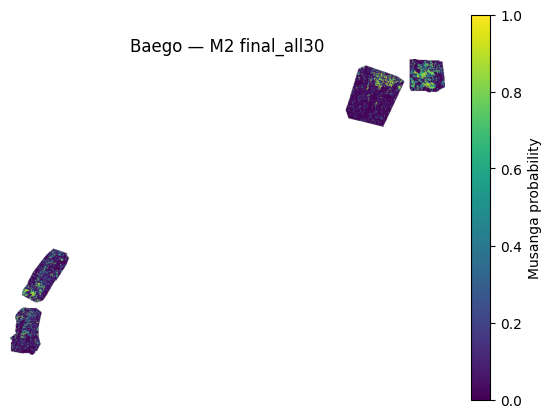

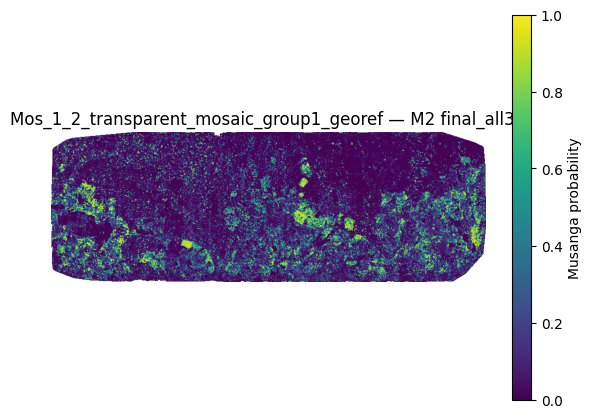

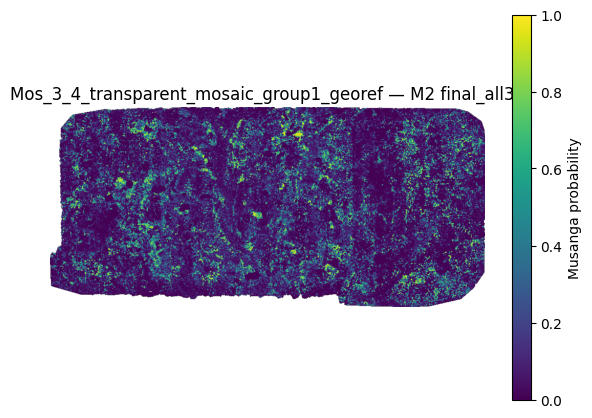

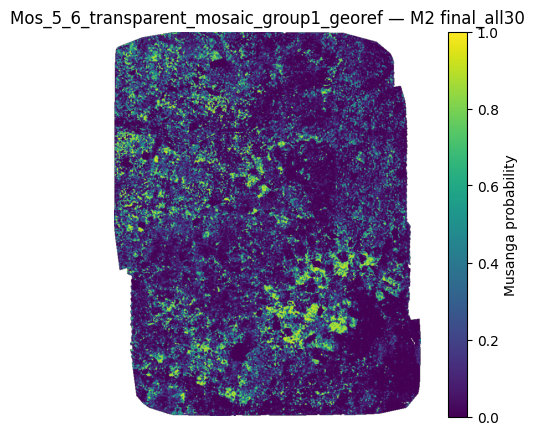

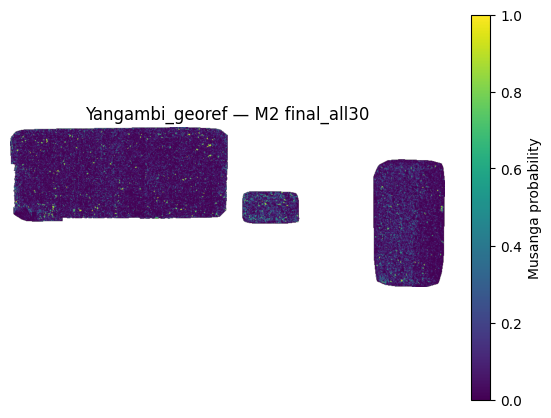

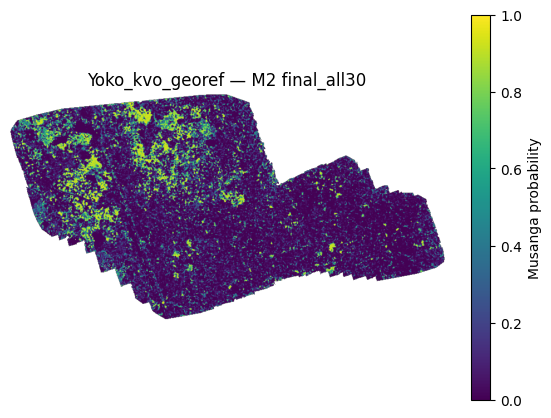

,mosaic,crs,width,height,file_GB,tested_windows,tested_valid_pixels,overview_valid_fraction
0,Baego.tif,EPSG:32635,89967,61291,0.30,180,0,0.044776
1,Mos_1_2_transparent_mosaic_group1_georef.tif,EPSG:32635,63924,22137,1.40,66,4194304,0.966773
2,Mos_3_4_transparent_mosaic_group1_georef.tif,EPSG:32635,53118,24438,1.26,72,4390912,0.925299
3,Mos_5_6_transparent_mosaic_group1_georef.tif,EPSG:32635,31639,39755,1.21,117,7536640,0.919347
4,Yangambi_georef.tif,EPSG:32635,101817,37433,1.46,111,359928,0.426829
5,Yoko_kvo_georef.tif,EPSG:32635,44359,23217,0.59,69,3997696,0.602299


Before ecological analysis: inspect seam lines and MOS3–4 qualitatively in QGIS/ArcGIS.


In [7]:
import matplotlib.pyplot as plt
from rasterio.enums import Resampling
QA=[]
for name in RUN_MOSAICS:
    spec=spec_for(name)
    output=MAPS/(Path(name).stem+"_M2_" + MODEL_MODE + "_probability_u16_FULL.tif")
    assert full_ok(output,spec),("Incomplete/missing output",name)
    with rasterio.open(MOSAICS[name]) as original,rasterio.open(output) as pred:
        # Source and output must match EXACTLY in native raster grid.
        assert pred.width==original.width and pred.height==original.height
        assert pred.crs==original.crs and pred.transform==original.transform
        # Validate validity at distributed output blocks, including stripe seams.
        points=[(0,0),(original.height-1,original.width-1),
                (original.height//2,original.width//2)]
        for seam in range(STRIPE,original.height,STRIPE):
            for delta in (-1,0,1):
                if 0<=seam+delta<original.height:
                    points.append((seam+delta,original.width//2))
        tested=0;good=0
        for rr,cc in points:
            h=min(256,original.height-rr)
            w=min(256,original.width-cc)
            win=Window(cc,rr,w,h)
            rgb=original.read([1,2,3],window=win,masked=True)
            mask=valid_rgb(rgb)
            z=pred.read(1,window=win)
            assert np.array_equal(z!=NODATA,mask),(
                "Full-map validity mask differs from NB02B-style RGB validity",name,rr,cc)
            assert np.all(z[mask]<=SCALE)
            tested+=1;good+=int(mask.sum())
        factor=max(1,math.ceil(max(pred.width,pred.height)/900))
        overview=pred.read(1,out_shape=(max(1,pred.height//factor),
                     max(1,pred.width//factor)),resampling=Resampling.nearest)
        shown=np.where(overview==NODATA,np.nan,overview.astype("float32")/SCALE)
        fig,ax=plt.subplots(figsize=(7,5))
        im=ax.imshow(shown,cmap="viridis",vmin=0,vmax=1)
        fig.colorbar(im,ax=ax,label="Musanga probability")
        ax.set_title(Path(name).stem+" — M2 " + MODEL_MODE)
        ax.set_axis_off()
        fig.savefig(OUT/(Path(name).stem+"_overview.png"),dpi=140,bbox_inches="tight")
        plt.show();plt.close(fig)
        QA.append(dict(mosaic=name,crs=str(pred.crs),width=pred.width,
            height=pred.height,file_GB=round(output.stat().st_size/1e9,2),
            tested_windows=tested,tested_valid_pixels=good,
            overview_valid_fraction=float(np.mean(overview!=NODATA))))
display(pd.DataFrame(QA))
(OUT/"03_final_QA.json").write_text(json.dumps(QA,indent=2))
print("Before ecological analysis: inspect seam lines and MOS3–4 qualitatively in QGIS/ArcGIS.")
